In [ ]:
Practical No:2
Roll no: 46
Title:Predict the price of the Uber ride from a given pickup point to the 
agreed drop-off location. Perform following tasks: 
1. Pre-process the dataset. 2. Identify outliers. 3. Check the 
correlation. 4. Implement linear regression and ridge, Lasso 
regression models. 5. Evaluate the models and compare their 
respective scores like R2, RMSE, etc. Dataset link: 
https://www.kaggle.com/datasets/yasserh/uber-fares-dataset 

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [24]:
df = pd.read_csv("uber.csv")

print(df.head())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [25]:
print("Shape of dataset:", df.shape)

Shape of dataset: (200000, 9)


In [26]:
print(df.columns)

Index(['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'passenger_count'],
      dtype='str')


In [27]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB
None


In [28]:
print(df.describe())

         Unnamed: 0    fare_amount  pickup_longitude  pickup_latitude  \
count  2.000000e+05  200000.000000     200000.000000    200000.000000   
mean   2.771250e+07      11.359955        -72.527638        39.935885   
std    1.601382e+07       9.901776         11.437787         7.720539   
min    1.000000e+00     -52.000000      -1340.648410       -74.015515   
25%    1.382535e+07       6.000000        -73.992065        40.734796   
50%    2.774550e+07       8.500000        -73.981823        40.752592   
75%    4.155530e+07      12.500000        -73.967154        40.767158   
max    5.542357e+07     499.000000         57.418457      1644.421482   

       dropoff_longitude  dropoff_latitude  passenger_count  
count      199999.000000     199999.000000    200000.000000  
mean          -72.525292         39.923890         1.684535  
std            13.117408          6.794829         1.385997  
min         -3356.666300       -881.985513         0.000000  
25%           -73.991407        

In [29]:
print(df.isnull().sum())

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [33]:
df.dropna(inplace=True)

In [34]:
print(df.isnull().sum())

key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
hour                 0
day                  0
month                0
year                 0
day_of_week          0
dtype: int64


In [35]:
df = df[df["fare_amount"] > 0]

In [36]:
df = df[df["passenger_count"] > 0]

In [37]:
df = df[
    (df["fare_amount"] > 0) &
    (df["passenger_count"] > 0) &
    (df["pickup_latitude"].between(40, 42)) &
    (df["dropoff_latitude"].between(40, 42)) &
    (df["pickup_longitude"].between(-75, -72)) &
    (df["dropoff_longitude"].between(-75, -72))
]

In [38]:
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

outliers = df[
    (df["fare_amount"] < Q1 - 1.5 * IQR) |
    (df["fare_amount"] > Q3 + 1.5 * IQR)
]

print("Number of outliers:", len(outliers))

Number of outliers: 16708


In [39]:
df = df[
    df["fare_amount"].between(
        max(0, Q1 - 1.5 * IQR),
        Q3 + 1.5 * IQR
    )
]

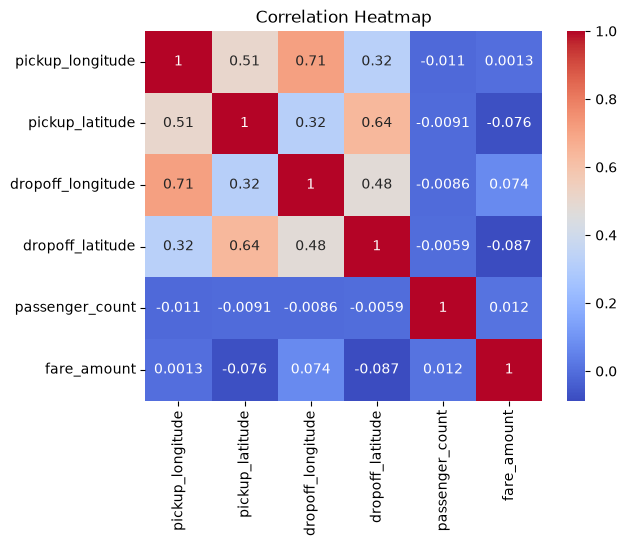

In [41]:
features = [
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "passenger_count"
]
sns.heatmap(df[features + ["fare_amount"]].corr(),
            annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


In [42]:
X = df[features]
y = df["fare_amount"]

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [44]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [45]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Lasso Regression": Lasso()
}

for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)

    print("\n", name)
    print("R2 Score:", round(r2_score(y_test, prediction), 3))
    print("RMSE:", round(np.sqrt(
        mean_squared_error(y_test, prediction)), 3))
    print("MAE:", round(mean_absolute_error(y_test, prediction), 3))


 Linear Regression
R2 Score: 0.031
RMSE: 4.069
MAE: 3.235

 Ridge Regression
R2 Score: 0.031
RMSE: 4.069
MAE: 3.235

 Lasso Regression
R2 Score: -0.0
RMSE: 4.134
MAE: 3.286
